<a href="https://colab.research.google.com/github/GavrilLaura/PMP-2026/blob/main/Lab05/pmp_tema4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#**Tema 4 – Laboratorul 5**

##**Retele Markov: independentă, predictie si restaurarea imaginilor**



### Exercițiul 1

**a)** A ⊥ C | B înseamnă că, odată ce cunoaștem B, C nu mai aduce nicio informație despre A: P(a | b, c) = P(a | b). Toată influența dintre A și C trece prin B.

**b)** Din regula produsului și A ⊥ C | B:
$$P(a,b,c) = P(b)\,P(a\mid b)\,P(c\mid a,b) = P(b)\,P(a\mid b)\,P(c\mid b)$$
Luăm $\phi_{AB}(a,b) = P(a\mid b)P(b) = P(a,b)$, $\phi_{BC}(b,c) = P(c\mid b)$ și $Z = 1$. Ambele sunt strict pozitive, deoarece distribuția este strict pozitivă. Deci $P(a,b,c) = \frac{1}{Z}\phi_{AB}(a,b)\,\phi_{BC}(b,c)$.

**c)** Reciproc, presupunem $P(a,b,c) = \frac{1}{Z}\phi_{AB}(a,b)\phi_{BC}(b,c)$. Notăm $f(b) = \sum_a \phi_{AB}(a,b)$ și $g(b) = \sum_c \phi_{BC}(b,c)$. Atunci $P(b) = \frac{1}{Z} f(b)\,g(b)$ și
$$P(a,c\mid b) = \frac{P(a,b,c)}{P(b)} = \frac{\phi_{AB}(a,b)}{f(b)}\cdot\frac{\phi_{BC}(b,c)}{g(b)}$$
Sumând după c obținem $P(a\mid b) = \frac{\phi_{AB}(a,b)}{f(b)}$, iar sumând după a obținem $P(c\mid b) = \frac{\phi_{BC}(b,c)}{g(b)}$. Deci $P(a,c\mid b) = P(a\mid b)\,P(c\mid b)$, adică A ⊥ C | B.

### Exercițiul 2

In [1]:
!pip install -q pgmpy

S1 are vecinii: ['S2', 'S3']
S2 are vecinii: ['S1', 'S4', 'S5']
S3 are vecinii: ['S1']
S4 are vecinii: ['S2']
S5 are vecinii: ['S2']
Graful este arbore (conex, fara cicluri): True


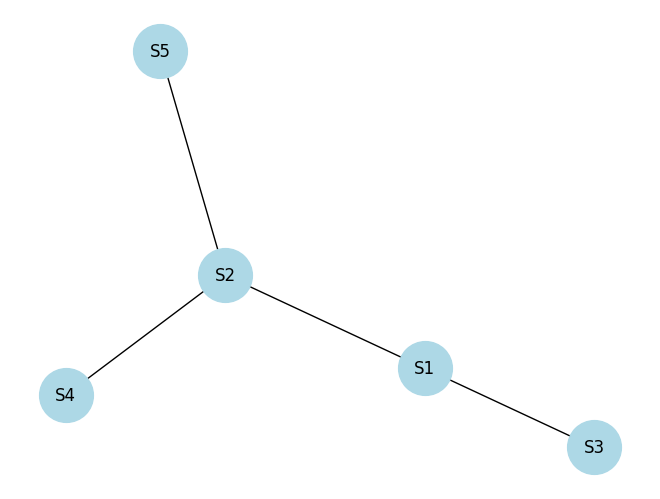

In [2]:
# a) Graful statiilor
import networkx as nx
import matplotlib.pyplot as plt

statii = ["S1", "S2", "S3", "S4", "S5"]
muchii = [("S1", "S2"), ("S1", "S3"), ("S2", "S4"), ("S2", "S5")]

graf = nx.Graph()
graf.add_nodes_from(statii)
graf.add_edges_from(muchii)

for s in statii:
    print(s, "are vecinii:", list(graf.neighbors(s)))
print("Graful este arbore (conex, fara cicluri):", nx.is_tree(graf))

nx.draw(graf, with_labels=True, node_size=1500, node_color="lightblue")
plt.savefig("graf_statii.png")
plt.show()

In [3]:
# b) Modelul Markov discret
from pgmpy.models import DiscreteMarkovNetwork
from pgmpy.factors.discrete import DiscreteFactor

vreme = ["Soare", "Ploaie", "Nori"]
p_initial = [0.5, 0.3, 0.2]
psi = [[0.7, 0.2, 0.1],
       [0.2, 0.6, 0.2],
       [0.1, 0.3, 0.6]]

model = DiscreteMarkovNetwork(muchii)

# factor unar pentru fiecare statie
for s in statii:
    factor_unar = DiscreteFactor([s], cardinality=[3], values=p_initial,
                                 state_names={s: vreme})
    model.add_factors(factor_unar)

# factor pereche pentru fiecare muchie (matricea psi scrisa pe un singur rand)
for (si, sj) in muchii:
    valori = []
    for rand in psi:
        for v in rand:
            valori.append(v)
    factor_pereche = DiscreteFactor([si, sj], cardinality=[3, 3], values=valori,
                                    state_names={si: vreme, sj: vreme})
    model.add_factors(factor_pereche)

print("Model valid:", model.check_model())

Model valid: True


### c)
$$P(s_1,\dots,s_5) = \frac{1}{Z}\prod_{i=1}^{5}\phi_i(s_i)\prod_{(i,j)\in E}\phi_{ij}(s_i,s_j)$$
cu $\phi_i = (0.5, 0.3, 0.2)$, $\phi_{ij}(s_i,s_j) = \Psi_{s_i,s_j}$ și E = {(S1,S2), (S1,S3), (S2,S4), (S2,S5)}. Graful modelului este cel de la a).

In [4]:
# d) Distributia marginala la statiile neobservate
from pgmpy.inference import VariableElimination

observatii = {"S1": "Nori", "S4": "Nori"}
infer = VariableElimination(model)

for s in ["S2", "S3", "S5"]:
    marginala = infer.query([s], evidence=observatii)
    marginala.normalize()      # la retele Markov rezultatul trebuie normalizat
    print(marginala)

/usr/local/lib/python3.13/dist-packages/pgmpy/estimators/__init__.py:4: FutureWarning: `pgmpy.estimators.StructureScore` is deprecated and will be removed in v1.3.0. Use `pgmpy.structure_score` instead.
  from .StructureScore import (


+------------+-----------+
| S2         |   phi(S2) |
+============+===========+
| S2(Soare)  |    0.0807 |
+------------+-----------+
| S2(Ploaie) |    0.2163 |
+------------+-----------+
| S2(Nori)   |    0.7030 |
+------------+-----------+
+------------+-----------+
| S3         |   phi(S3) |
+============+===========+
| S3(Soare)  |    0.1923 |
+------------+-----------+
| S3(Ploaie) |    0.3462 |
+------------+-----------+
| S3(Nori)   |    0.4615 |
+------------+-----------+
+------------+-----------+
| S5         |   phi(S5) |
+============+===========+
| S5(Soare)  |    0.2685 |
+------------+-----------+
| S5(Ploaie) |    0.3763 |
+------------+-----------+
| S5(Nori)   |    0.3552 |
+------------+-----------+


In [5]:
# e) MAP comun vs. maxime marginale
neobservate = ["S2", "S3", "S5"]

map_comun = infer.map_query(variables=neobservate, evidence=observatii)
print("MAP comun:      ", map_comun)

map_marginal = {}
for s in neobservate:
    marginala = infer.query([s], evidence=observatii)
    marginala.normalize()
    cel_mai_bun = 0
    for k in range(3):
        if marginala.values[k] > marginala.values[cel_mai_bun]:
            cel_mai_bun = k
    map_marginal[s] = vreme[cel_mai_bun]
print("Maxime marginale:", map_marginal)

0it [00:00, ?it/s]

MAP comun:       {'S3': 'Nori', 'S2': 'Nori', 'S5': 'Nori'}
Maxime marginale: {'S2': 'Nori', 'S3': 'Nori', 'S5': 'Ploaie'}


In [6]:
# Verificare: enumeram toate cele 3^3 = 27 de configuratii ale statiilor neobservate
import itertools

cel_mai_bun_scor = -1
cea_mai_buna = None

for valori in itertools.product(vreme, repeat=3):
    stare = {"S1": "Nori", "S4": "Nori", "S2": valori[0], "S3": valori[1], "S5": valori[2]}

    scor = 1
    for s in statii:
        scor = scor * p_initial[vreme.index(stare[s])]
    for (si, sj) in muchii:
        scor = scor * psi[vreme.index(stare[si])][vreme.index(stare[sj])]

    if scor > cel_mai_bun_scor:
        cel_mai_bun_scor = scor
        cea_mai_buna = stare

print("MAP prin enumerare:", cea_mai_buna)

MAP prin enumerare: {'S1': 'Nori', 'S4': 'Nori', 'S2': 'Nori', 'S3': 'Nori', 'S5': 'Nori'}


### Exercițiul 3

In [7]:
# a) Imaginea originala: patrat alb pe fond negru
import numpy as np
import matplotlib.pyplot as plt

original = np.zeros((5, 5), dtype=int)
original[1:4, 1:4] = 1
print(original)

[[0 0 0 0 0]
 [0 1 1 1 0]
 [0 1 1 1 0]
 [0 1 1 1 0]
 [0 0 0 0 0]]


Pixeli inversati: 3
[[0 0 0 0 0]
 [0 1 1 1 0]
 [0 1 1 1 1]
 [1 0 1 1 0]
 [0 0 0 0 0]]


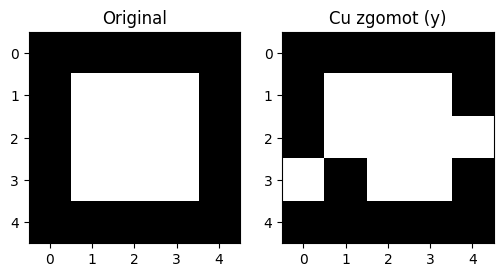

In [8]:
# b) Adaugam zgomot: inversam aproximativ 10% din pixeli
np.random.seed(0)
y = original.copy()
nr_inversati = 0

for i in range(5):
    for j in range(5):
        if np.random.random() < 0.1:
            y[i, j] = 1 - y[i, j]
            nr_inversati = nr_inversati + 1

print("Pixeli inversati:", nr_inversati)
print(y)

fig, ax = plt.subplots(1, 2, figsize=(6, 3))
ax[0].imshow(original, cmap="gray", vmin=0, vmax=1)
ax[0].set_title("Original")
ax[1].imshow(y, cmap="gray", vmin=0, vmax=1)
ax[1].set_title("Cu zgomot (y)")
plt.savefig("imagini_b.png")
plt.show()

In [9]:
# c) Vecinii unui pixel si energia E(x; y)
def vecini(i, j):
    rezultat = []
    if i > 0:
        rezultat.append((i - 1, j))   # sus
    if i < 4:
        rezultat.append((i + 1, j))   # jos
    if j > 0:
        rezultat.append((i, j - 1))   # stanga
    if j < 4:
        rezultat.append((i, j + 1))   # dreapta
    return rezultat

def energie(x, y, lam):
    E = 0
    # termenul de fidelitate fata de observatie
    for i in range(5):
        for j in range(5):
            E = E + lam * (x[i, j] - y[i, j]) ** 2
    # termenul de netezire: fiecare muchie o singura data (vecinul din dreapta si cel de jos)
    for i in range(5):
        for j in range(5):
            if j < 4:
                E = E + (x[i, j] - x[i, j + 1]) ** 2
            if i < 4:
                E = E + (x[i, j] - x[i + 1, j]) ** 2
    return E

### c)
$E(x;y) = \lambda\sum_i (x_i - y_i)^2 + \sum_{(i,j)\in E}(x_i - x_j)^2$
- primul termen: fidelitate față de imaginea observată;
- al doilea termen: netezire (vecinii diferiți sunt penalizați).

Potențiale: $\phi_i(x_i) = e^{-\lambda(x_i - y_i)^2}$, $\phi_{ij}(x_i,x_j) = e^{-(x_i - x_j)^2}$, iar $P(x \mid y) \propto e^{-E(x;y)}$.

In [10]:
# d) ICM: fiecare pixel ia valoarea care minimizeaza energia locala
def energie_locala(x, y, lam, i, j, valoare):
    E = lam * (valoare - y[i, j]) ** 2
    for (vi, vj) in vecini(i, j):
        E = E + (valoare - x[vi, vj]) ** 2
    return E

def icm(y, lam):
    x = y.copy()                  # pornim de la imaginea observata
    schimbat = True
    while schimbat:               # repetam pana nu se mai schimba niciun pixel
        schimbat = False
        for i in range(5):
            for j in range(5):
                e0 = energie_locala(x, y, lam, i, j, 0)
                e1 = energie_locala(x, y, lam, i, j, 1)
                if e0 < e1:
                    nou = 0
                elif e1 < e0:
                    nou = 1
                else:
                    nou = x[i, j]    # la egalitate pastram valoarea
                if nou != x[i, j]:
                    x[i, j] = nou
                    schimbat = True
    return x

x_icm = icm(y, 1)
print(x_icm)
print("Energia imaginii cu zgomot:", energie(y, y, 1))
print("Energia dupa ICM:         ", energie(x_icm, y, 1))

[[0 0 0 0 0]
 [0 1 1 1 0]
 [0 1 1 1 1]
 [0 0 1 1 0]
 [0 0 0 0 0]]
Energia imaginii cu zgomot: 16
Energia dupa ICM:          14


Imaginea cu zgomot: pixeli gresiti = 3
lambda = 0.3 : pixeli gresiti = 6
lambda = 1 : pixeli gresiti = 2
lambda = 3 : pixeli gresiti = 3


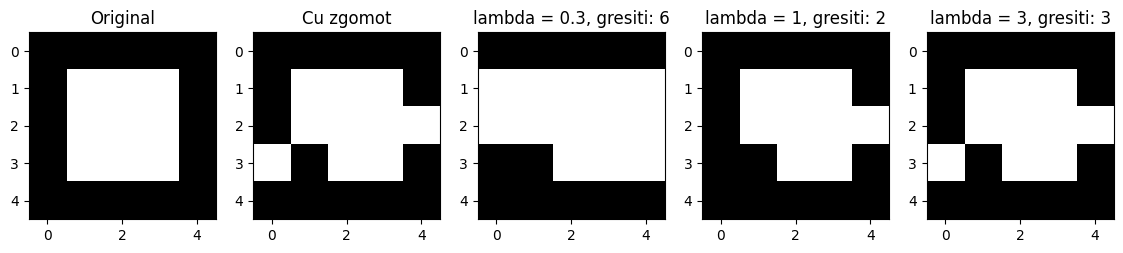

In [11]:
# e) Comparam mai multe valori ale lui lambda
valori_lam = [0.3, 1, 3]

fig, ax = plt.subplots(1, 5, figsize=(14, 3))
ax[0].imshow(original, cmap="gray", vmin=0, vmax=1)
ax[0].set_title("Original")
ax[1].imshow(y, cmap="gray", vmin=0, vmax=1)
ax[1].set_title("Cu zgomot")

print("Imaginea cu zgomot: pixeli gresiti =", np.sum(y != original))
for k in range(3):
    lam = valori_lam[k]
    x_rec = icm(y, lam)
    gresite = np.sum(x_rec != original)
    print("lambda =", lam, ": pixeli gresiti =", gresite)
    ax[k + 2].imshow(x_rec, cmap="gray", vmin=0, vmax=1)
    ax[k + 2].set_title("lambda = " + str(lam) + ", gresiti: " + str(gresite))

plt.savefig("imagini_e.png")
plt.show()

Am folosit ICM (metodă aproximativă), care poate găsi un minim local, nu neapărat MAP-ul global.
- λ = 0.3: netezirea domină și imaginea este „spălată”, cu prea mulți pixeli schimbați (6 greșiți).
- λ = 1: compromis bun; zgomotul izolat este eliminat (2 greșiți, față de 3 inițial).
- λ = 3: fidelitatea domină și imaginea rămâne aproape identică cu cea cu zgomot (3 greșiți).

Un λ mic dă greutate termenului de vecinătate (netezire), iar un λ mare dă greutate observației (fidelitate).